# 1. 데이터 불러오기 & 첫인상 확인

가장 먼저 할 일은 데이터를 불러와서 "생김새"를 눈으로 확인하는 것입니다.
- 행/열이 몇 개인지
- 컬럼(변수)이 뭐가 있는지
- 데이터 타입은 뭔지
- 결측치(빈 값)가 있는지

이 대회의 특이한 점: `train.csv`에는 정답(Class)이 없고, `val.csv`에만 정답이 있습니다. 그래서 지도학습을 그대로 쓰기 어렵고, 비지도/반지도 이상탐지 접근이 필요할 수 있습니다. 이 부분은 데이터를 직접 보면서 같이 확인해봐요.

In [11]:
# 데이터 분석에 기본적으로 쓰이는 라이브러리를 불러옵니다
import pandas as pd   # 표 형태(데이터프레임) 데이터를 다루는 라이브러리
import numpy as np    # 수치 계산용 라이브러리

# CSV 파일을 읽어서 데이터프레임으로 불러옵니다
train = pd.read_csv('../data/train.csv')  # 정답(Class) 없는 학습용 데이터
val = pd.read_csv('../data/val.csv')      # 정답(Class) 있는 검증용 데이터
test = pd.read_csv('../data/test.csv')    # 정답 없는, 우리가 예측해서 제출해야 할 데이터

# 각 데이터의 크기(행 수, 열 수)를 먼저 확인합니다
print('train shape:', train.shape)
print('val shape:', val.shape)
print('test shape:', test.shape)

train shape: (113842, 31)
val shape: (28462, 32)
test shape: (142503, 31)


In [12]:
import matplotlib.pyplot as plt

# Windows 기본 한글 폰트(맑은 고딕)로 지정해서 그래프 제목/축의 한글이 깨지지 않게 합니다
plt.rcParams['font.family'] = 'Malgun Gothic'
# 한글 폰트를 쓰면 마이너스(-) 기호가 깨지는 경우가 있어서, 이를 방지하는 옵션입니다
plt.rcParams['axes.unicode_minus'] = False

In [13]:
# train 데이터의 위쪽 5개 행을 표로 예쁘게 출력해서 어떤 값들이 들어있는지 확인합니다
display(train.head())

,ID,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,V29,V30
0,3,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,4.983721,-0.994972
1,4,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,1.418291,-0.994972
2,6,-0.425966,0.960523,1.141109,-0.168252,0.420987,-0.029728,0.476201,0.260314,-0.568671,...,-0.208254,-0.559825,-0.026398,-0.371427,-0.232794,0.105915,0.253844,0.081080,-0.256131,-0.994960
3,8,-0.644269,1.417964,1.074380,-0.492199,0.948934,0.428118,1.120631,-3.807864,0.615375,...,1.943465,-1.015455,0.057504,-0.649709,-0.415267,-0.051634,-1.206921,-1.085339,0.262698,-0.994901
4,9,-0.894286,0.286157,-0.113192,-0.271526,2.669599,3.721818,0.370145,0.851084,-0.392048,...,-0.073425,-0.268092,-0.204233,1.011592,0.373205,-0.384157,0.011747,0.142404,0.994900,-0.994901


## 2. 기초 통계량 확인 (평균, 표준편차, 왜도, 첨도)

각 변수(V1~V30)가 어떤 값 범위와 분포 모양을 갖는지 숫자로 먼저 확인합니다.
- 평균(mean), 표준편차(std): 값이 어디에 몰려있고 얼마나 퍼져있는지
- 왜도(skewness): 분포가 한쪽으로 치우쳤는지 (0에 가까우면 좌우 대칭)
- 첨도(kurtosis): 분포 끝(꼬리)에 극단값이 많은지 (정규분포보다 뾰족한 정도)

PCA로 만들어진 변수들이라 평균이 0 근처일 가능성이 높은데, 실제로 그런지 직접 확인해봐요.

In [14]:
# ID는 그냥 식별 번호일 뿐 분석 대상이 아니므로 제외하고, V로 시작하는 컬럼만 고릅니다
feature_cols = [c for c in train.columns if c.startswith('V')]

# .describe()는 컬럼별 개수/평균/표준편차/최소값/사분위수/최대값을 한 번에 요약해줍니다
# .T로 전치해서 변수 이름(V1~V30)이 행으로 오게 정리합니다 (30개 변수를 세로로 보기 편하게)
train_desc = train[feature_cols].describe().T

# skew()는 왜도, kurtosis()는 첨도를 계산해서 describe 결과에 컬럼으로 추가합니다
train_desc['skew'] = train[feature_cols].skew()
train_desc['kurtosis'] = train[feature_cols].kurtosis()

print('=== train 기초통계량 (V1~V30) ===')
display(train_desc)

=== train 기초통계량 (V1~V30) ===


,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
V1,113842.0,1.972910e-04,1.951060,-56.407510,-0.923479,0.012074,1.315373,2.454930,-3.425612,37.503207
V2,113842.0,1.288795e-03,1.651064,-72.715728,-0.595602,0.066390,0.801687,21.467203,-5.081937,109.491912
V3,113842.0,9.717363e-03,1.496916,-32.454198,-0.883877,0.183868,1.037120,4.187811,-1.879981,18.862813
V4,113842.0,-4.169208e-03,1.412633,-5.600607,-0.853728,-0.019359,0.742208,16.491217,0.631852,2.422964
V5,113842.0,4.749962e-04,1.367533,-42.147898,-0.689853,-0.054060,0.614214,34.801666,-0.713394,60.374903
V6,113842.0,5.141158e-03,1.330583,-26.160506,-0.766094,-0.272436,0.405285,23.917837,1.316038,12.901768
V7,113842.0,5.769024e-03,1.204111,-41.506796,-0.552071,0.039036,0.568750,44.054461,0.580322,100.880878
V8,113842.0,-2.450588e-03,1.185504,-50.943369,-0.209492,0.020970,0.328303,20.007208,-8.223307,192.649969
V9,113842.0,-2.107069e-03,1.095415,-13.434066,-0.647477,-0.052157,0.590705,10.392889,0.630811,3.666194
V10,113842.0,5.209413e-03,1.071337,-24.403185,-0.533477,-0.090810,0.455287,15.331742,1.741154,26.525020


## 3. V28 분포 직접 눈으로 확인하기

왜도가 높게 나온 V28을 히스토그램으로 그려서, 정말로 한쪽으로 치우친 "긴 꼬리" 모양인지 확인합니다.
평균(mean)과 중앙값(median)을 같이 표시해서, 왜도가 클 때 이 둘이 왜 달라지는지도 함께 봅니다.

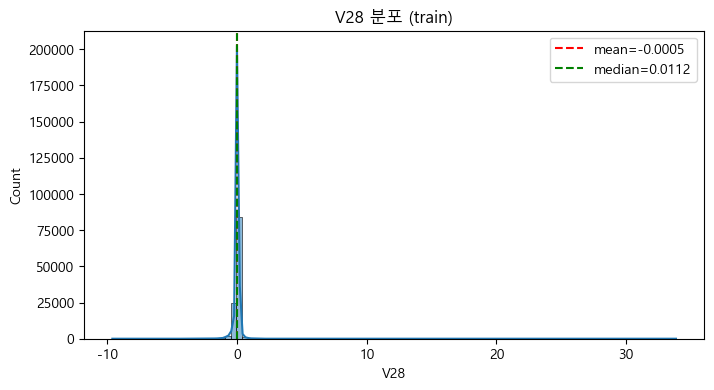

In [15]:
import matplotlib.pyplot as plt  # 그래프를 그리는 라이브러리
import seaborn as sns            # matplotlib을 더 예쁘게 감싸주는 시각화 라이브러리

v28_mean = train['V28'].mean()      # V28의 평균
v28_median = train['V28'].median()  # V28의 중앙값 (값을 순서대로 세웠을 때 정가운데 값)

plt.figure(figsize=(8, 4))
sns.histplot(train['V28'], bins=100, kde=True)  # 히스토그램 + 부드러운 분포 곡선(kde)
plt.axvline(v28_mean, color='red', linestyle='--', label=f'mean={v28_mean:.4f}')     # 평균 위치에 빨간 점선
plt.axvline(v28_median, color='green', linestyle='--', label=f'median={v28_median:.4f}')  # 중앙값 위치에 초록 점선
plt.title('V28 분포 (train)')
plt.legend()
plt.show()

## 4. V28의 극단값 개수 세어보기

"평균 ± 3×표준편차" 범위를 벗어나는 값을 통계학에서 흔히 극단값(이상치 후보)으로 봅니다.
V28에서 이 범위를 벗어나는 값이 몇 개나 있는지, 전체의 몇 %인지 확인합니다.

In [16]:
v28_mean = train['V28'].mean()
v28_std = train['V28'].std()

# 평균에서 표준편차 3배 이상 떨어진 값을 극단값으로 정의합니다 (3-sigma 규칙)
lower = v28_mean - 3 * v28_std
upper = v28_mean + 3 * v28_std

is_extreme = (train['V28'] < lower) | (train['V28'] > upper)  # 범위를 벗어나는지 True/False로 표시
n_extreme = is_extreme.sum()  # True의 개수 = 극단값 개수

print(f'정상 범위: {lower:.3f} ~ {upper:.3f}')
print(f'극단값 개수: {n_extreme}개 (전체의 {n_extreme / len(train) * 100:.3f}%)')

정상 범위: -1.069 ~ 1.068
극단값 개수: 1112개 (전체의 0.977%)


## 5. V28 극단값이 실제 사기와 관련 있을까?

train 기준으로 정한 "정상 범위"(-1.069 ~ 1.068)를 val에도 그대로 적용해서, 그 범위를 벗어난 거래 중
실제 사기(Class=1) 비율이 정상 거래(Class=0)보다 높은지 비교합니다.

만약 사기 쪽에서 극단값 비율이 뚜렷하게 높다면, V28의 극단값이 사기 탐지에 쓸모있는 신호라는 뜻입니다.

In [17]:
# train에서 계산했던 정상 범위를 그대로 val에 적용합니다 (val로 다시 계산하면 안 됨 - train 기준을 유지)
val_is_extreme = (val['V28'] < lower) | (val['V28'] > upper)

# Class(0=정상, 1=사기)별로 극단값 비율이 얼마나 다른지 비교합니다
extreme_rate = val.groupby('Class').apply(lambda g: val_is_extreme[g.index].mean())

print('Class별 V28 극단값 비율:')
print(f'  정상(0): {extreme_rate[0] * 100:.2f}%')
print(f'  사기(1): {extreme_rate[1] * 100:.2f}%')

Class별 V28 극단값 비율:
  정상(0): 1.01%
  사기(1): 13.33%


C:\Users\이성진\AppData\Local\Temp\ipykernel_27412\3051844039.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  extreme_rate = val.groupby('Class').apply(lambda g: val_is_extreme[g.index].mean())


## 6. V1~V30 전체로 확장: 어떤 변수가 사기와 가장 관련 있을까?

방금 V28에서 했던 것과 똑같은 방식(train 기준 3-시그마 범위 → val에 적용 → 정상/사기 극단값 비율 비교)을
V1~V30 전체에 반복해서, 정상 대비 사기의 극단값 비율이 몇 배(배율)인지 순위표로 정리합니다.

사기 건수가 30개뿐이라 배율 수치 자체보다는 "어떤 변수들이 상위권에 자주 보이는지" 경향을 보는 게 더 의미 있습니다.

In [18]:
feature_cols = [c for c in train.columns if c.startswith('V')]

results = []
for col in feature_cols:
    # train 기준으로 평균/표준편차를 구하고, 그 범위(3-시그마)를 val 검사에 그대로 적용합니다
    mean = train[col].mean()
    std = train[col].std()
    lo, hi = mean - 3 * std, mean + 3 * std

    is_ext = (val[col] < lo) | (val[col] > hi)  # val에서 극단값 여부
    normal_rate = is_ext[val['Class'] == 0].mean()  # 정상 거래 중 극단값 비율
    fraud_rate = is_ext[val['Class'] == 1].mean()    # 사기 거래 중 극단값 비율
    fraud_count = int(is_ext[val['Class'] == 1].sum())  # 사기 중 실제 극단값 '건수' (표본이 작아서 비율보다 건수가 더 정직한 정보)

    results.append({
        '변수': col,
        '정상_극단값비율(%)': round(normal_rate * 100, 2),
        '사기_극단값비율(%)': round(fraud_rate * 100, 2),
        '사기_극단값건수(30건중)': fraud_count,
        '배율(사기/정상)': round(fraud_rate / normal_rate, 1) if normal_rate > 0 else np.nan,
    })

result_df = pd.DataFrame(results).sort_values('배율(사기/정상)', ascending=False)
display(result_df)

,변수,정상_극단값비율(%),사기_극단값비율(%),사기_극단값건수(30건중),배율(사기/정상)
10,V11,0.15,63.33,19,428.7
17,V18,0.52,53.33,16,103.2
2,V3,0.66,63.33,19,96.3
15,V16,0.72,53.33,16,74.0
13,V14,1.14,83.33,25,73.4
16,V17,0.91,66.67,20,72.9
9,V10,1.08,70.00,21,65.0
11,V12,1.27,80.00,24,63.2
3,V4,1.08,63.33,19,58.7
8,V9,0.73,40.00,12,54.9


## 7. 상위 신호 변수들을 박스플롯으로 확인

배율 순위표에서 상위권이었던 8개 변수(V14, V12, V10, V17, V16, V3, V11, V18)를 정상(Class=0) vs 사기(Class=1)로
나눠서 박스플롯으로 그립니다. 박스가 서로 많이 벌어져 있을수록 그 변수가 두 그룹을 잘 구분한다는 뜻입니다.

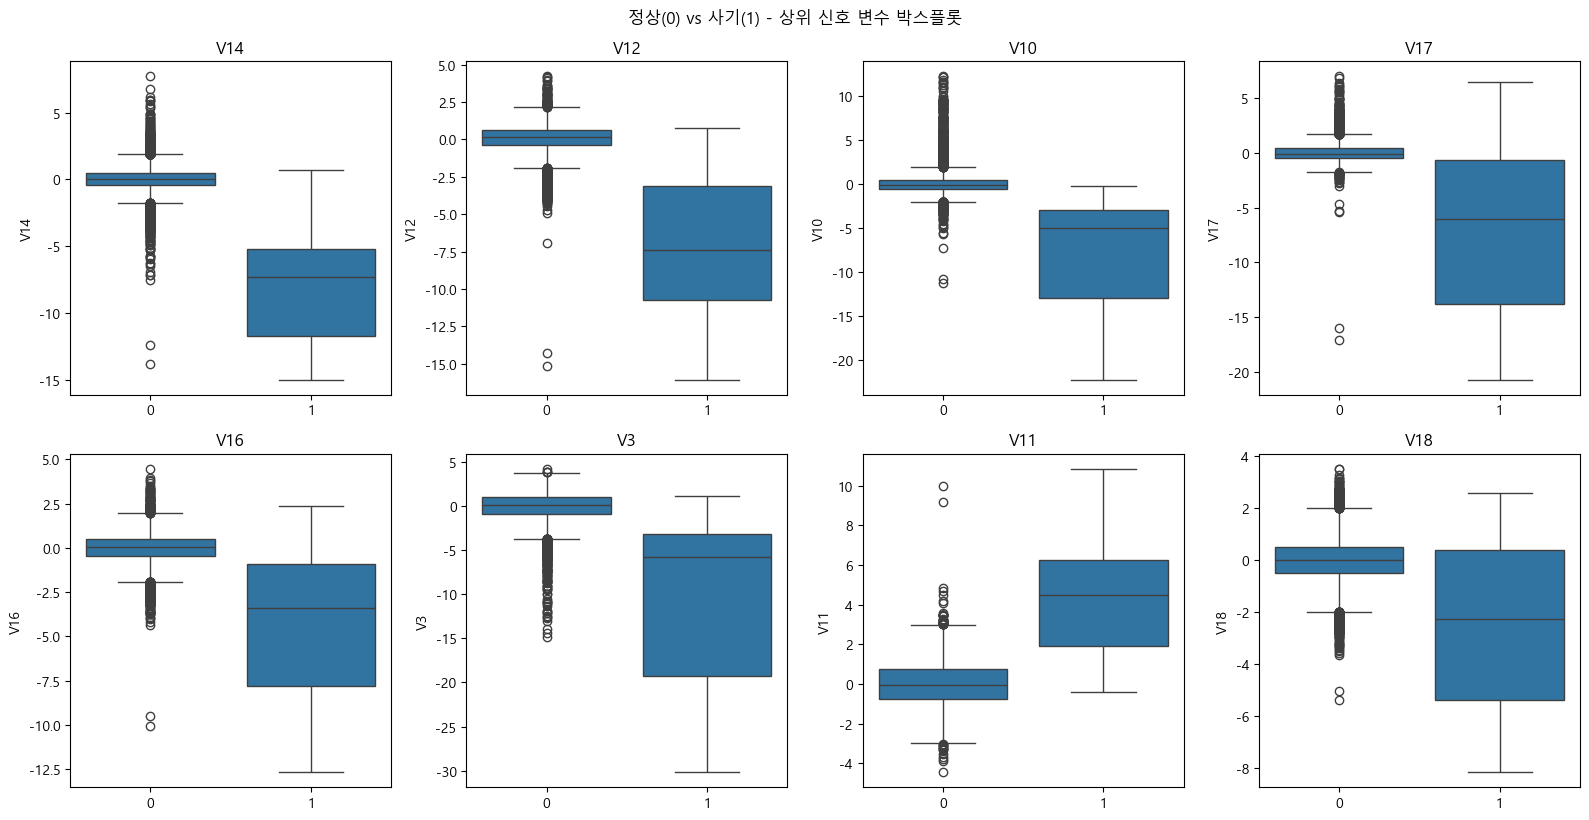

In [19]:
top_features = ['V14', 'V12', 'V10', 'V17', 'V16', 'V3', 'V11', 'V18']  # 배율 순위표 상위 변수들

fig, axes = plt.subplots(2, 4, figsize=(16, 8))  # 2행 4열 격자로 8개 그래프를 한 번에 그립니다
axes = axes.flatten()  # 2차원 격자를 1차원 리스트로 펴서 반복문으로 접근하기 쉽게 합니다

for i, col in enumerate(top_features):
    sns.boxplot(data=val, x='Class', y=col, ax=axes[i])  # Class(0/1)별로 박스플롯을 그립니다
    axes[i].set_title(col)
    axes[i].set_xlabel('')

plt.tight_layout()  # 그래프끼리 겹치지 않게 간격을 자동 조정합니다
plt.suptitle('정상(0) vs 사기(1) - 상위 신호 변수 박스플롯', y=1.02)
plt.show()

## 8. V1~V30 상관관계 히트맵

PCA로 만든 변수들은 서로 상관관계가 거의 없도록(직교하도록) 설계됩니다. 실제로 그런지 train 데이터로 확인합니다.
색이 진할수록(빨강/파랑) 상관관계가 강하고, 흰색에 가까울수록 무상관입니다.

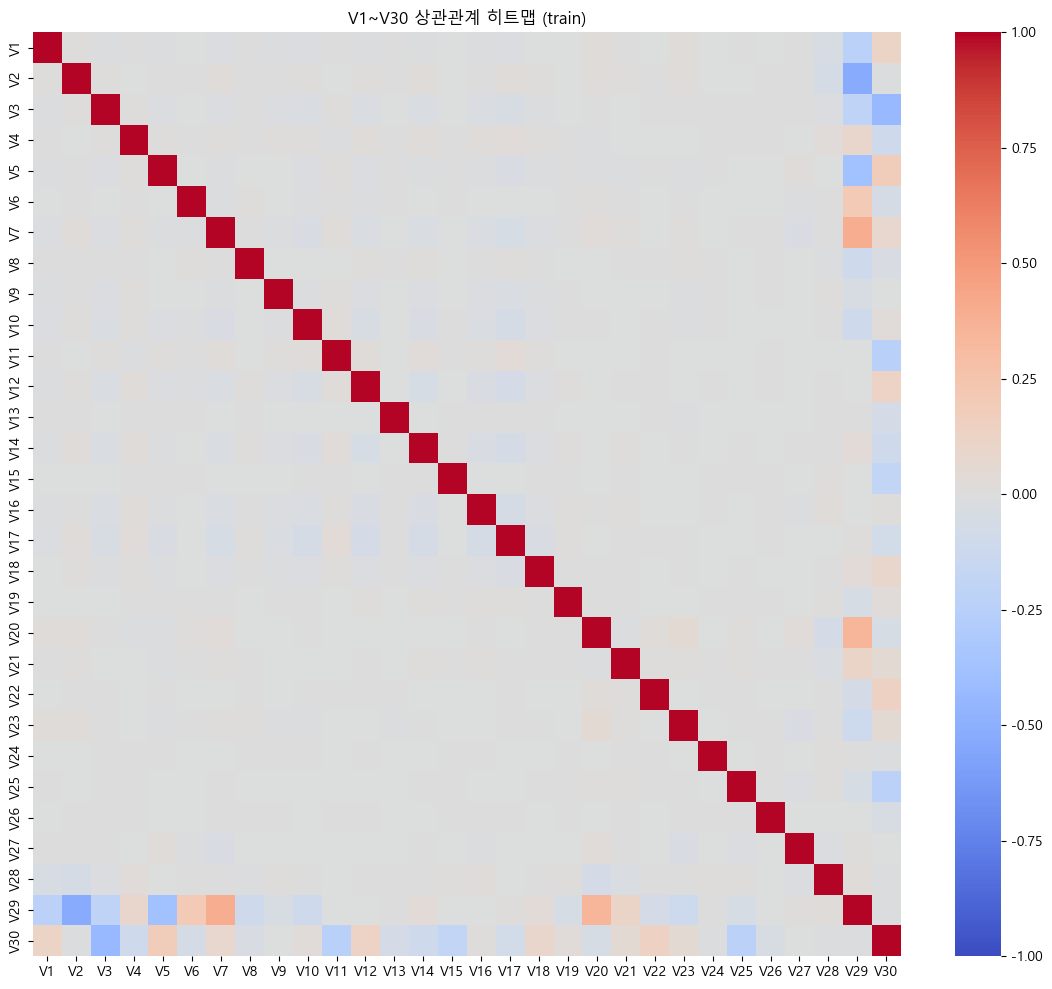

대각선을 제외한 최대 절대 상관계수: 0.5307


In [20]:
corr = train[feature_cols].corr()  # V1~V30 간 상관계수 행렬 (30x30)

plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap='coolwarm', center=0, vmin=-1, vmax=1)  # center=0: 0을 흰색 기준으로 색칠
plt.title('V1~V30 상관관계 히트맵 (train)')
plt.show()

# 대각선(자기 자신과의 상관관계=1)을 제외하고, 나머지 중 절대값이 가장 큰 상관계수를 찾습니다
corr_no_diag = corr.copy()
np.fill_diagonal(corr_no_diag.values, 0)  # 대각선만 0으로 바꿔서 계산에서 제외
max_corr = corr_no_diag.abs().max().max()
print(f'대각선을 제외한 최대 절대 상관계수: {max_corr:.4f}')

## 9. val 클래스 불균형 시각화

정상(Class=0)과 사기(Class=1)가 얼마나 불균형한지 막대그래프로 확인합니다.
막대를 실제 크기 그대로(로그 스케일 없이) 그려서, 사기 건수가 얼마나 압도적으로 적은지 시각적으로 체감합니다.
이 불균형이 심할수록, 나중에 macro-F1 같은 평가지표를 쓰는 이유가 더 분명해집니다.

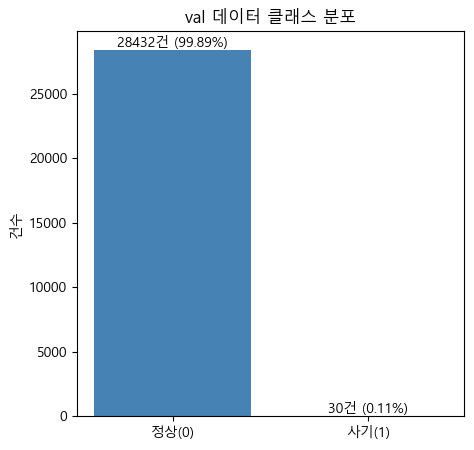

In [21]:
class_counts = val['Class'].value_counts().sort_index()  # 인덱스(0, 1) 순서로 정렬
labels = ['정상(0)', '사기(1)']

plt.figure(figsize=(5, 5))
bars = plt.bar(labels, class_counts.values, color=['steelblue', 'crimson'])
plt.title('val 데이터 클래스 분포')
plt.ylabel('건수')

# 막대 위에 실제 건수와 비율(%)을 글자로 표시합니다
for bar, count in zip(bars, class_counts.values):
    pct = count / len(val) * 100
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f'{count}건 ({pct:.2f}%)', ha='center', va='bottom')

plt.show()

## 10. train vs val vs test 분포 비교

대표 변수 4개(V1, V3, V14, V28)를 골라서 train/val/test 세 데이터의 분포를 겹쳐 그립니다.
세 데이터의 행 개수가 다르므로(113,842 / 28,462 / 142,503), 단순 개수(count) 대신
전체 대비 비율인 밀도(density)로 정규화해서 그려야 공평하게 비교할 수 있습니다.

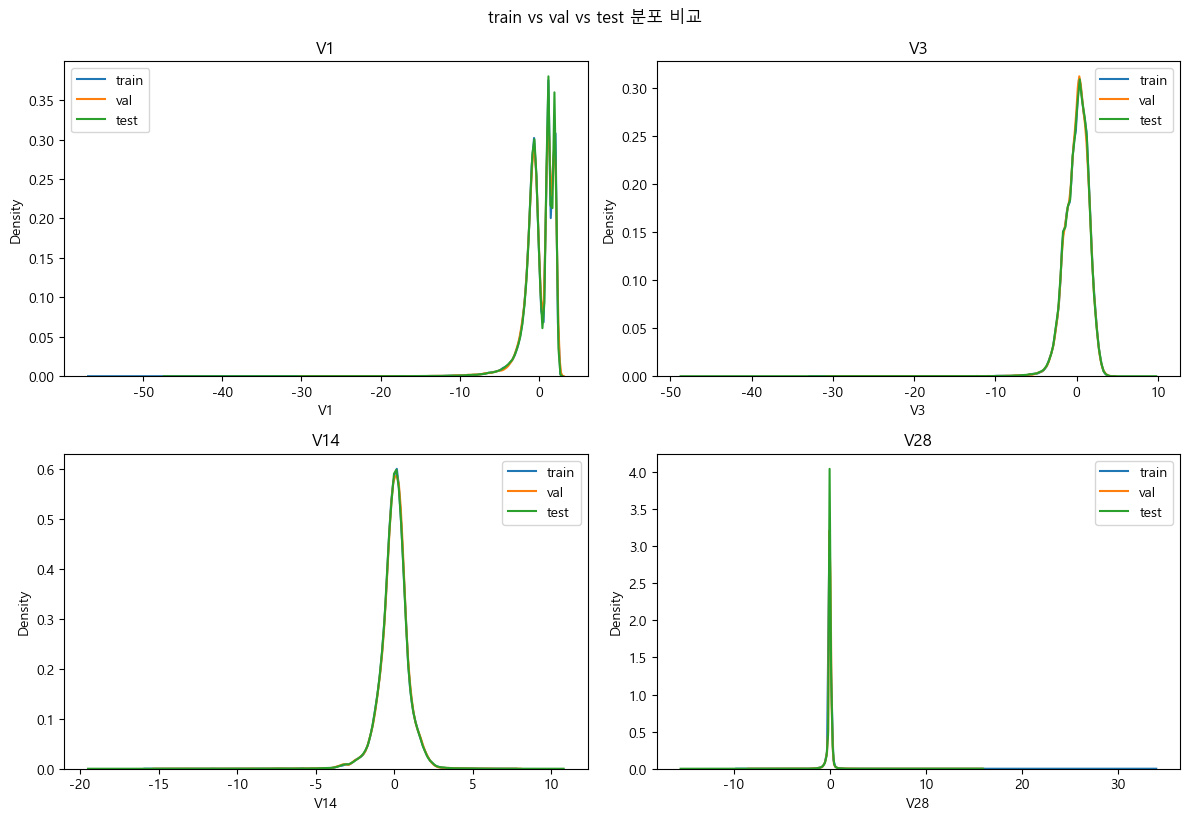

In [22]:
compare_cols = ['V1', 'V3', 'V14', 'V28']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, col in enumerate(compare_cols):
    # stat='density'로 세 데이터의 행 개수 차이를 보정해서 같은 기준으로 비교합니다
    sns.kdeplot(train[col], ax=axes[i], label='train', fill=False)
    sns.kdeplot(val[col], ax=axes[i], label='val', fill=False)
    sns.kdeplot(test[col], ax=axes[i], label='test', fill=False)
    axes[i].set_title(col)
    axes[i].legend()

plt.tight_layout()
plt.suptitle('train vs val vs test 분포 비교', y=1.02)
plt.show()

## 11. KS-test로 train vs test 분포 차이 검정

KS(Kolmogorov-Smirnov) 검정은 두 분포가 얼마나 다른지를 0~1 사이의 통계량(KS statistic)으로 나타냅니다.
0에 가까울수록 두 분포가 비슷하고, 1에 가까울수록 많이 다릅니다.
V1~V30 전체에 대해 train과 test를 비교해서 KS 통계량이 큰 순서로 정렬합니다.

In [23]:
from scipy.stats import ks_2samp  # 두 표본이 같은 분포에서 나왔는지 검정하는 함수

ks_results = []
for col in feature_cols:
    stat, pvalue = ks_2samp(train[col], test[col])  # train과 test 분포를 비교
    ks_results.append({'변수': col, 'KS통계량': round(stat, 4), 'p-value': pvalue})

ks_df = pd.DataFrame(ks_results).sort_values('KS통계량', ascending=False)
display(ks_df)

,변수,KS통계량,p-value
29,V30,0.0053,0.055900
24,V25,0.0052,0.063787
2,V3,0.0048,0.112927
12,V13,0.0048,0.108012
7,V8,0.0045,0.146777
8,V9,0.0044,0.173727
22,V23,0.0041,0.248438
18,V19,0.0039,0.302778
13,V14,0.0037,0.351436
16,V17,0.0036,0.398394


## 12. Phase 1 EDA 요약

**데이터 성격**
- train(113,842행, 라벨 없음) / val(28,462행, Class 있음) / test(142,503행, 라벨 없음)
- train/val/test는 KS-test 결과(모든 변수 KS통계량 < 0.006, p-value 전부 > 0.05) 통계적으로 동일한 분포 → 일반화 걱정 없이 모델링 가능

**변수(V1~V30) 특징**
- V1~V28: PCA 성분다운 특징 — 평균 0에 가까움, 서로 거의 무상관, std가 V1(1.95)에서 V28(0.36)까지 점점 작아지는 규칙적 흐름
- V29, V30: 다른 변수들과 패턴이 다름 (평균·표준편차가 이질적이고, 여러 V와 상관관계 최대 0.53) → 순수 PCA 성분이 아니라 원본 Amount/Time류로 추정, 추후 모델링 시 별도로 취급 고려

**클래스 불균형**
- val 기준 정상 28,432건 vs 사기 30건 (0.105%) → 극심한 불균형, macro-F1 등 불균형에 강한 평가지표 필요

**사기 판별 신호**
- 3-시그마 극단값 비율로 변수별 순위를 매긴 결과, V14·V12·V10·V17·V16·V3·V11·V18이 정상 대비 사기의 극단값 비율이 60배~430배 높음 (단, 사기 표본이 30건뿐이라 정확한 배율보다는 경향으로 해석)
- 박스플롯으로 확인한 결과 대부분 변수에서 사기 거래가 0에서 멀리 밀려나 있고 분산도 큼 (V11만 방향이 반대: 사기가 양수 쪽)
- 여러 변수가 동시에 신호를 보이므로, 단일 변수 임계값보다 다변량 접근(Mahalanobis, Isolation Forest 등)이 유리할 것으로 예상

**다음 단계 (Phase 2)**
- 평가지표(혼동행렬/precision/recall/F1/macro-F1) 직접 구현 및 이해
- Mahalanobis distance 기반 통계적 베이스라인 모델 구축, threshold 튜닝, 첫 제출